# Brain Tumor MRI Classification with ResNet50

This notebook builds and trains a deep learning model to classify brain tumors using MRI images. It uses transfer learning with ResNet50.

## Table of Contents
1. [Imports and Setup](#imports)
2. [Internet Connectivity Check](#internet)
3. [Set Random Seeds for Reproducibility](#seeds)
4. [Define Labels and Directories](#labels)
5. [Data Loading and Preprocessing](#data)
6. [Data Augmentation](#augmentation)
7. [Model Building](#model)
8. [Callbacks Setup](#callbacks)
9. [Model Training](#training)
10. [Model Evaluation](#evaluation)

## 1. imports and setup

In [1]:
import numpy as np
import os
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tqdm import tqdm
from skimage.transform import resize

from sklearn.utils import shuffle 
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense
from tensorflow.keras.models import load_model, Model
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

import seaborn as sns

import random
import socket

2025-04-28 17:13:59.554206: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1745860439.893777      31 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1745860439.977092      31 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


## 2. internet connectivity check

In [2]:
def check_internet(host="8.8.8.8", port=53, timeout=3):
    """
    Checks internet connectivity by attempting to connect to a well-known DNS server.

    Parameters:
        host (str): Host to connect to.
        port (int): Port number.
        timeout (int): Timeout duration in seconds.

    Returns:
        bool: True if connected, False otherwise.
    """
    try:
        socket.setdefaulttimeout(timeout)
        socket.socket(socket.AF_INET, socket.SOCK_STREAM).connect((host, port))
        return True
    except socket.error as ex:
        print(f"Internet connectivity check failed: {ex}")
        return False

internet_available = check_internet()

if not internet_available:
    print("No internet connection detected. The model will be loaded without pre-trained weights.")
else:
    print("Internet connection detected. Proceeding to download pre-trained weights.")

Internet connection detected. Proceeding to download pre-trained weights.


<a id='seeds'></a>
## 3. Set Random Seeds for Reproducibility

set seeds for various libraries to make sure we can reproduce results.

In [3]:
seed = 42
np.random.seed(seed)
tf.random.set_seed(seed)
random.seed(seed)

<a id='labels'></a>
## 4. Define Labels and Directories

specify the class labels and the directories containing training and testing data.

In [4]:
labels = ['glioma', 'meningioma', 'notumor', 'pituitary']

train_dir = '/kaggle/input/brain-tumor-mri-dataset/Training/'
test_dir = '/kaggle/input/brain-tumor-mri-dataset/Testing/'

In [5]:

# exhaustive duplicate / leak detector                    

import os, hashlib
from collections import defaultdict

# tiny helper 
def file_sha1(path, chunk=8192):
    h = hashlib.sha1()
    with open(path, 'rb') as f:
        for c in iter(lambda: f.read(chunk), b''):
            h.update(c)
    return h.hexdigest()


def scan_for_duplicates(train_dir, test_dir, *, keep_one_copy=True):
    """
    Parameters
    ----------
    train_dir, test_dir : str
    keep_one_copy       : bool  – keep a single copy (True) or drop *all* copies (False)

    Returns
    -------
    skip_train_paths : set of str – files to ignore when loading training split
    skip_test_paths  : set of str – files to ignore when loading testing split
    stats            : dict       – counters for pretty printing
    """
    # sha1 → {'train': [paths…], 'test': [paths…]}
    buckets = defaultdict(lambda: {'train': [], 'test': []})

    for split, base in (('train', train_dir), ('test', test_dir)):
        for root, _, files in os.walk(base):
            for f in files:
                p   = os.path.join(root, f)
                sha = file_sha1(p)
                buckets[sha][split].append(p)

    skip_train_paths, skip_test_paths = set(), set()
    stats = dict(
        dup_train=0, dup_test=0,
        leak_hashes=0, leak_files_train=0, leak_files_test=0
    )

    for sha, d in buckets.items():
        t_paths = d['train']
        s_paths = d['test']

        # duplicates inside each split
        if len(t_paths) > 1:                      # duplicates in Training
            stats['dup_train'] += len(t_paths) - (1 if keep_one_copy else 0)
            skip_train_paths.update(t_paths if not keep_one_copy else t_paths[1:])

        if len(s_paths) > 1:                      # duplicates in Testing
            stats['dup_test'] += len(s_paths) - (1 if keep_one_copy else 0)
            skip_test_paths.update(s_paths if not keep_one_copy else s_paths[1:])

        # cross-split leakage 
        if t_paths and s_paths:                   # same SHA-1 in both splits
            stats['leak_hashes']      += 1
            stats['leak_files_train'] += len(t_paths) - (0 if keep_one_copy else len(t_paths))
            stats['leak_files_test']  += len(s_paths)

            # convention: keep the training copy, drop all test copies
            skip_test_paths.update(s_paths)
            if not keep_one_copy:                 # drop train copies as well
                skip_train_paths.update(t_paths)

    return skip_train_paths, skip_test_paths, stats


# run the scan 
train_dir = '/kaggle/input/brain-tumor-mri-dataset/Training'
test_dir  = '/kaggle/input/brain-tumor-mri-dataset/Testing'

skip_train_paths, skip_test_paths, st = scan_for_duplicates(train_dir, test_dir,
                                                            keep_one_copy=True)

print("──────────────────── duplicate / leak report ────────────────────")
print(f"↺ duplicates INSIDE Training : {st['dup_train']}")
print(f"↺ duplicates INSIDE Testing  : {st['dup_test']}")
print(f"↹ leakage across splits      : {st['leak_hashes']} SHA-1s"
      f"  → {st['leak_files_test']} test files skipped")
print("──────────────────────────────────────────────────────────────────")

# you may also want these numbers later:
n_skip_train = len(skip_train_paths)
n_skip_test  = len(skip_test_paths)

──────────────────── duplicate / leak report ────────────────────
↺ duplicates INSIDE Training : 191
↺ duplicates INSIDE Testing  : 27
↹ leakage across splits      : 79 SHA-1s  → 103 test files skipped
──────────────────────────────────────────────────────────────────


## 5. Data Loading and Preprocessing

load images from the directories, preprocess them, and prepare the dataset for training.

In [6]:
# load_data  +  leak-skip logging

import os
import numpy as np
import matplotlib.pyplot as plt
from skimage.transform import resize
from tqdm import tqdm

def load_data(directory, label_list, image_size, *, skip_paths=None, log_skipped=False):
    """
    Load and preprocess MRI images.

    Parameters
    ----------
    directory   : str   – split root (e.g. train_dir or test_dir)
    label_list  : list  – ordered class names
    image_size  : int   – target square size (e.g. 224)
    skip_paths  : set/None – absolute file paths to ignore (train-test leaks)
    log_skipped : bool  – print how many files were skipped
    
    Returns
    -------
    images  : np.ndarray  (N, H, W, 3) float32
    labels  : np.ndarray  (N,)          int
    skipped : int         number of files ignored because of skip_paths
    """
    images, labels_encoded = [], []
    skipped = 0

    for class_idx, label in enumerate(label_list):
        class_dir = os.path.join(directory, label)
        if not os.path.isdir(class_dir):
            if log_skipped:
                print(f"[WARN] directory '{class_dir}' is missing.")
            continue

        for fname in tqdm(os.listdir(class_dir),
                          desc=f"Loading {label} from {os.path.basename(directory)}"):
            img_path = os.path.join(class_dir, fname)

            if skip_paths and img_path in skip_paths:
                skipped += 1
                continue

            try:
                img = plt.imread(img_path)

                # ensure 3-channel RGB
                if img.ndim == 2:               # grayscale
                    img = np.stack([img] * 3, -1)
                elif img.shape[-1] == 4:        # RGBA
                    img = img[..., :3]

                # rescale to 0-255 if the array is in 0-1
                if img.dtype in (np.float32, np.float64) and img.max() <= 1.0:
                    img *= 255.0
                elif img.dtype in (np.uint8, np.int32, np.int64) and img.max() <= 1:
                    img *= 255

                img = img.astype(np.float32)
                img = resize(img, (image_size, image_size, 3), anti_aliasing=True)

                images.append(img)
                labels_encoded.append(class_idx)

            except Exception as e:
                if log_skipped:
                    print(f"[WARN] could not read {img_path}: {e}")

    if log_skipped:
        split_name = os.path.basename(directory)
        print(f"Skipped {skipped} file(s) in '{split_name}'")

    return np.array(images, dtype=np.float32), np.array(labels_encoded), skipped



# usage

image_size = 224                 # ResNet-50 requirement

#

print("Loading Training Data …")
X_train, Y_train, skipped_train = load_data(train_dir, labels, image_size,
                                            skip_paths=skip_train_paths,
                                            log_skipped=True)

print("\nLoading Testing Data …")
X_test,  Y_test, skipped_test  = load_data(test_dir,  labels, image_size,
                                           skip_paths=skip_test_paths,
                                           log_skipped=True)

print(f"\n✅ Expected to skip {n_skip_train} train and {n_skip_test} test files.")
print(f"   Actually skipped {skipped_train} train and {skipped_test} test files.")

Loading Training Data …


Loading pituitary from Training: 100%|██████████| 1457/1457 [00:37<00:00, 38.86it/s]


Skipped 191 file(s) in 'Training'

Loading Testing Data …


Loading pituitary from Testing: 100%|██████████| 300/300 [00:06<00:00, 44.71it/s]


Skipped 106 file(s) in 'Testing'

✅ Expected to skip 191 train and 106 test files.
   Actually skipped 191 train and 106 test files.


In [7]:
print("After Loading and Before Preprocessing:")
print("X_train min:", X_train.min(), "max:", X_train.max())
print("X_test min:", X_test.min(), "max:", X_test.max())

After Loading and Before Preprocessing:
X_train min: 0.0 max: 255.0
X_test min: 0.0 max: 255.0


### Apply ResNet50 Preprocessing

ResNet50's `preprocess_input` function to both training and testing data.

In [8]:
print("\nApplying ResNet50 Preprocessing...")
X_train = preprocess_input(X_train)
X_test = preprocess_input(X_test)


Applying ResNet50 Preprocessing...


### Shuffle Training Data

we shuffle training data to ensure that batches are mixed during training.

In [9]:
print("\nShuffling Training Data...")
X_train, Y_train = shuffle(X_train, Y_train, random_state=42)


Shuffling Training Data...


### Split Data into Training and Validation Sets

we reserve a portion of the training data for validation to monitor model performance during training.

In [10]:
print("Splitting Data into Training and Validation Sets...")
X_train, X_valid, Y_train, Y_valid = train_test_split(
    X_train, Y_train, test_size=0.1, random_state=42, stratify=Y_train
)

Splitting Data into Training and Validation Sets...


### Display Class Distribution

we check the distribution of classes in training, validation, and testing sets to identify any potential imbalance.

In [11]:
print("\nClass Distribution in Training Set:")
unique, counts = np.unique(Y_train, return_counts=True)
for label, count in zip(unique, counts):
    print(f"{labels[label]}: {count}")

print("\nClass Distribution in Validation Set:")
unique, counts = np.unique(Y_valid, return_counts=True)
for label, count in zip(unique, counts):
    print(f"{labels[label]}: {count}")

print("\nClass Distribution in Test Set:")
unique, counts = np.unique(Y_test, return_counts=True)
for label, count in zip(unique, counts):
    print(f"{labels[label]}: {count}")


Class Distribution in Training Set:
glioma: 1189
meningioma: 1199
notumor: 1280
pituitary: 1300

Class Distribution in Validation Set:
glioma: 132
meningioma: 134
notumor: 142
pituitary: 145

Class Distribution in Test Set:
glioma: 299
meningioma: 302
notumor: 309
pituitary: 295


### Convert Labels to Categorical (One-Hot Encoding)

we convert integer labels to one-hot encoded vectors for multi-class classification.

In [12]:
print("Converting Labels to Categorical...")
y_train_new = to_categorical(Y_train, num_classes=4)
y_valid_new = to_categorical(Y_valid, num_classes=4)
y_test_new = to_categorical(Y_test, num_classes=4)

Converting Labels to Categorical...


## 6. Data Augmentation

Enhance the diversity of the training data using various augmentation techniques to improve model generalization.

In [13]:
print("\nSetting Up Data Augmentation...")
datagen = ImageDataGenerator(
    rotation_range=30,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.15,
    zoom_range=0.15,
    horizontal_flip=True,
    fill_mode='nearest'
)
datagen.fit(X_train)
train_generator = datagen.flow(X_train, y_train_new, batch_size=32, shuffle=True)


Setting Up Data Augmentation...


### Compute Class Weights to Handle Class Imbalance

we assign weights to classes to address any imbalance, making sure the model doesn't favor majority classes.

In [14]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(Y_train),
    y=Y_train
)
class_weights_dict = {i : class_weights[i] for i in range(len(labels))}
print("\nComputed Class Weights:", class_weights_dict)


Computed Class Weights: {0: 1.0445752733389402, 1: 1.035863219349458, 2: 0.9703125, 3: 0.9553846153846154}


## 7. Model Building

we construct the model using ResNet50 as the base, adding custom layers on top for classification.

In [ ]:
print("\nBuilding the Model...")
def build_model(image_size, labels, internet_available):
    """
    Builds and compiles the model based on ResNet50 architecture.
    
    Parameters:
        image_size (int): Size of the input images.
        labels (list): List of class labels.
        internet_available (bool): Flag indicating internet connectivity for pre-trained weights.
    
    Returns:
        tensorflow.keras.Model: Compiled Keras model.
    """
    try:
        if internet_available:
            # load ResNet50 model with pre-trained weights, exclude top layers
            base_model = ResNet50(input_shape=(image_size, image_size, 3), include_top=False, weights='imagenet')
            print("ResNet50 loaded with pre-trained ImageNet weights.")
        else:
            # load ResNet50 model without pre-trained weights
            base_model = ResNet50(input_shape=(image_size, image_size, 3), include_top=False, weights=None)
            print("ResNet50 loaded without pre-trained weights.")
    except Exception as e:
        print("Error loading ResNet50:", e)
        print("Proceeding with ResNet50 without pre-trained weights.")
        base_model = ResNet50(input_shape=(image_size, image_size, 3), include_top=False, weights=None)
    
    # freeze all layers in the base model initially
    for layer in base_model.layers:
        layer.trainable = False
    
    # if using pre-trained weights, unfreeze the last 30 layers for fine-tuning
    if internet_available:
        for layer in base_model.layers[-30:]:
            layer.trainable = True
        print("Unfroze the last 30 layers of ResNet50 for fine-tuning.")
    
    # build the model using Functional API
    inputs = keras.Input(shape=(image_size, image_size, 3))
    x = base_model(inputs, training=True)
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.5)(x)
    x = Dense(256, activation='relu')(x)  # Increased neurons
    x = Dropout(0.5)(x)
    outputs = Dense(len(labels), activation='softmax')(x)
    model = Model(inputs, outputs)
    
    # compile the model with Adam optimiser
    print("Compiling the Model...")
    model.compile(optimizer=Adam(learning_rate=1e-4),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
    
    # Model summary
    model.summary()
    
    return model

model = build_model(image_size, labels, internet_available)


Building the Model...


I0000 00:00:1745860664.172341      31 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1745860664.172971      31 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
ResNet50 loaded with pre-trained ImageNet weights.
Unfroze the last 30 layers of ResNet50 for fine-tuning.
Compiling the Model...


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ resnet50 (Functional)                │ (None, 7, 7, 2048)          │      23,587,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 2048)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 2048)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │         524,544 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 4)                   │           1,028 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,113,284 (91.98 MB)

 Trainable params: 14,975,748 (57.13 MB)

 Non-trainable params: 9,137,536 (34.86 MB)

In [16]:
print(model)

<Functional name=functional, built=True>


## 8. Callbacks Setup

we define callbacks to improve training, such as early stopping, model checkpointing, and learning rate reduction.

In [17]:
print("\nSetting Up Callbacks...")
early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)
checkpoint = ModelCheckpoint('/kaggle/working/Bmodel.keras',  # Updated file extension
                             monitor='val_loss',
                             save_best_only=True,
                             verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=5, min_lr=1e-6, verbose=1)


Setting Up Callbacks...


## 9. Model Training

we train the model using the augmented data generator, applying the defined callbacks and class weights.

In [18]:
print("\nStarting Model Training...")
history = model.fit(
    datagen.flow(X_train, y_train_new, batch_size=32),
    epochs=100, 
    validation_data=(X_valid, y_valid_new),
    callbacks=[early_stopping, checkpoint, reduce_lr],
    steps_per_epoch=len(X_train) // 32,
    class_weight=class_weights_dict,
    verbose=1
)


Starting Model Training...
Epoch 1/100


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
I0000 00:00:1745860687.834725      96 service.cc:148] XLA service 0x7feaf8002120 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1745860687.835959      96 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1745860687.835978      96 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1745860689.773865      96 cuda_dnn.cc:529] Loaded cuDNN version 90300


  1/155 ━━━━━━━━━━━━━━━━━━━━ 1:16:37 30s/step - accuracy: 0.1875 - loss: 2.3998

I0000 00:00:1745860698.679764      96 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 328ms/step - accuracy: 0.6431 - loss: 0.9624
Epoch 1: val_loss improved from inf to 0.19461, saving model to /kaggle/working/Bmodel.keras
155/155 ━━━━━━━━━━━━━━━━━━━━ 91s 399ms/step - accuracy: 0.6440 - loss: 0.9600 - val_accuracy: 0.9349 - val_loss: 0.1946 - learning_rate: 1.0000e-04
Epoch 2/100
  1/155 ━━━━━━━━━━━━━━━━━━━━ 24s 161ms/step - accuracy: 0.8750 - loss: 0.5987

/usr/lib/python3.11/contextlib.py:158: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self.gen.throw(typ, value, traceback)



Epoch 2: val_loss did not improve from 0.19461
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8750 - loss: 0.5987 - val_accuracy: 0.9349 - val_loss: 0.1987 - learning_rate: 1.0000e-04
Epoch 3/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 283ms/step - accuracy: 0.9081 - loss: 0.2503
Epoch 3: val_loss improved from 0.19461 to 0.16172, saving model to /kaggle/working/Bmodel.keras
155/155 ━━━━━━━━━━━━━━━━━━━━ 49s 302ms/step - accuracy: 0.9081 - loss: 0.2502 - val_accuracy: 0.9584 - val_loss: 0.1617 - learning_rate: 1.0000e-04
Epoch 4/100
  1/155 ━━━━━━━━━━━━━━━━━━━━ 17s 111ms/step - accuracy: 0.9062 - loss: 0.1433
Epoch 4: val_loss improved from 0.16172 to 0.15348, saving model to /kaggle/working/Bmodel.keras
155/155 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.9062 - loss: 0.1433 - val_accuracy: 0.9602 - val_loss: 0.1535 - learning_rate: 1.0000e-04
Epoch 5/100
155/155 ━━━━━━━━━━━━━━━━━━━━ 0s 286ms/step - accuracy: 0.9397 - loss: 0.1757
Epoch 5: val_loss improved from 0.15348 to 0.11328,

In [19]:
# we fetch a few batches to verify
for _ in range(2):
    X_batch, y_batch = next(train_generator)
    print(f"Batch X shape: {X_batch.shape}, Batch y shape: {y_batch.shape}")

Batch X shape: (32, 224, 224, 3), Batch y shape: (32, 4)
Batch X shape: (32, 224, 224, 3), Batch y shape: (32, 4)


## 10. Model Evaluation

after training, evaluate the best model on the test data to assess its performance.

In [20]:
print("\nLoading the Best Model...")
try:
    model = load_model('Bmodel.keras') 
    print("Best model loaded successfully.")
except Exception as e:
    print("Error loading the best model:", e)
    print("Proceeding with the current model weights.")

print("Evaluating the Model on Test Data...")
test_loss, test_accuracy = model.evaluate(X_test, y_test_new, verbose=2)
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


Loading the Best Model...
Best model loaded successfully.
Evaluating the Model on Test Data...
38/38 - 13s - 333ms/step - accuracy: 0.9801 - loss: 0.0488
Test Accuracy: 98.01%
Test Loss: 0.0488


In [21]:
# debugging: Check if 'model' is defined
try:
    print(model)
except NameError:
    print("The 'model' variable is not defined. Please make sure all previous cells have been executed successfully.")

<Functional name=functional, built=True>


In [22]:
def deprocess_input_caffe(x):
    """
    Reverses the preprocessing applied to images for ResNet50 in 'caffe' mode.
    
    Parameters:
        x (numpy.ndarray): Preprocessed image data.
    
    Returns:
        numpy.ndarray: Deprocessed image suitable for display.
    """
    x = x.copy()
    # add the mean pixel value to each channel
    x[..., 0] += 103.939  # B channel
    x[..., 1] += 116.779  # G channel
    x[..., 2] += 123.68   # R channel
    # convert from BGR to RGB
    x = x[..., ::-1]
    # ensure the pixel values are in [0, 255]
    x = np.clip(x, 0, 255)
    return x.astype(np.uint8)

## 11. Visualising Model Predictions

we visualize some of the model's predictions alongside the true labels to understand its performance qualitatively.

38/38 ━━━━━━━━━━━━━━━━━━━━ 12s 190ms/step
Visualizing Model Predictions (Balanced Classes)...


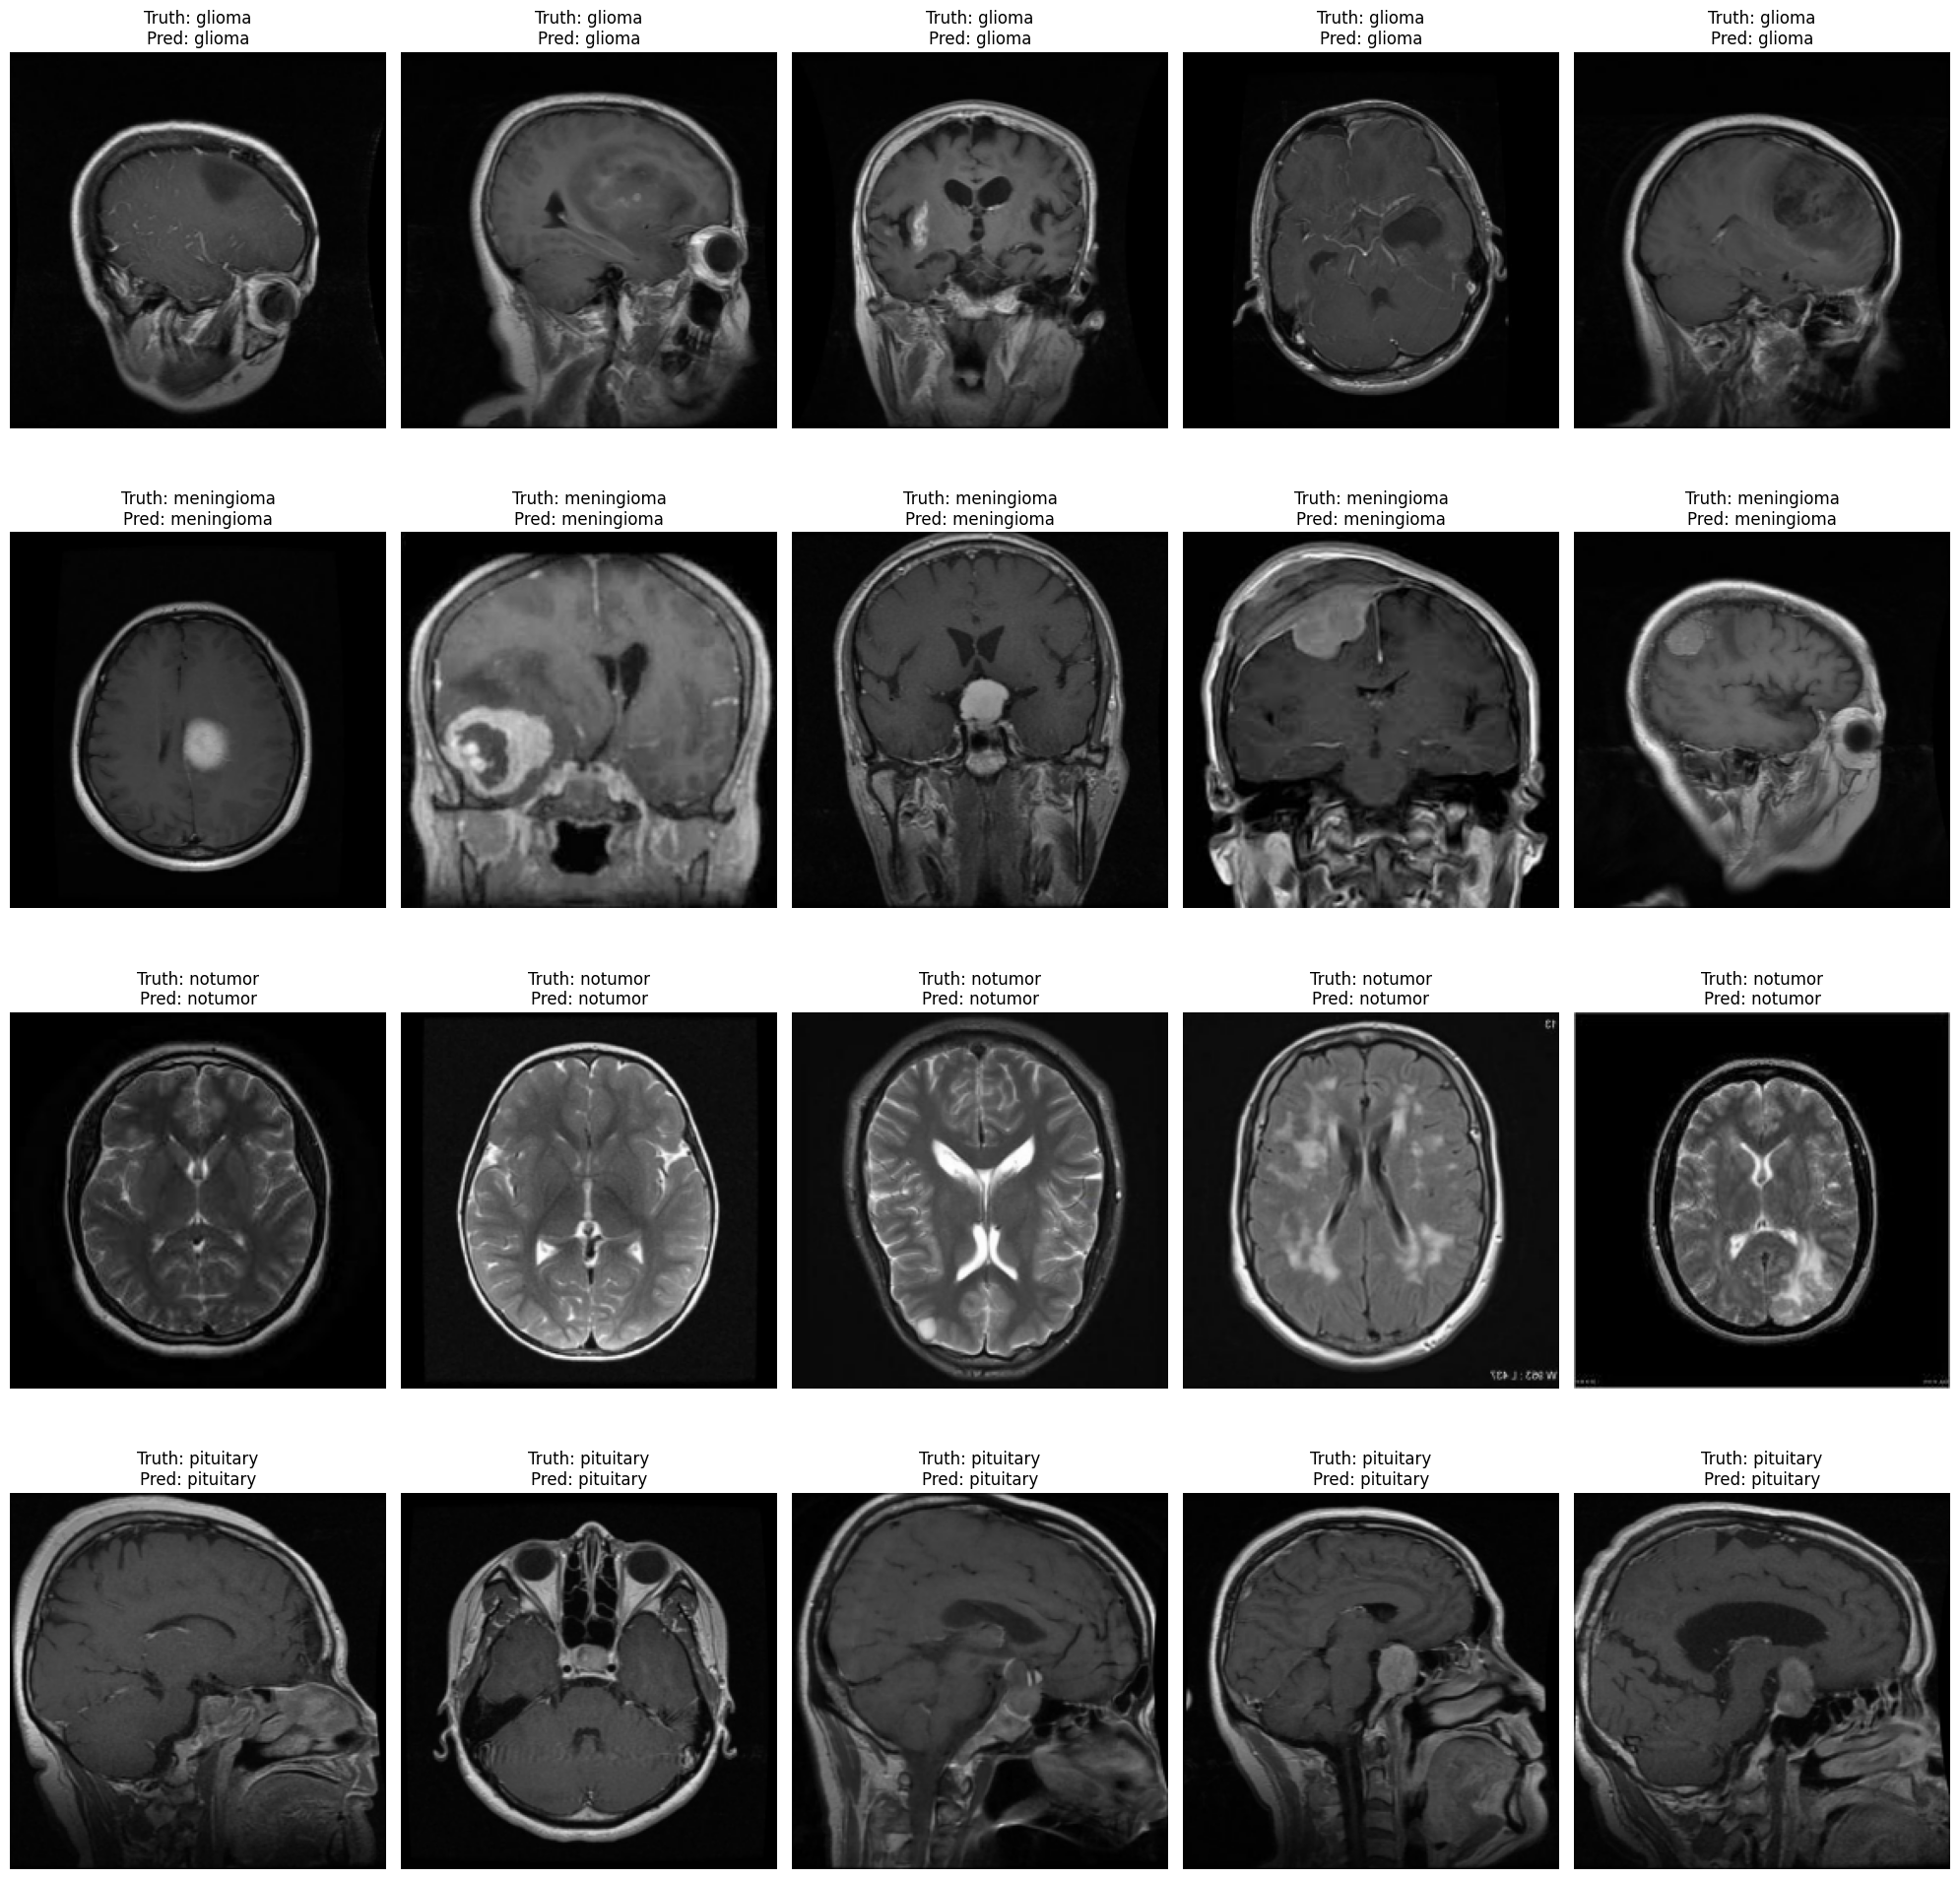

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# obtain predictions from the model
y_pred = model.predict(X_test)  # Predict probabilities
y_pred_classes = np.argmax(y_pred, axis=1)  # Convert to class indices

# define a function to sample balanced indices from each class
def sample_balanced_indices(Y_true, n_per_class=5):
    """
    Sample indices from all classes in a balanced manner.

    Parameters:
        Y_true (numpy.ndarray): Ground truth labels for the dataset.
        n_per_class (int): Number of samples to select per class.

    Returns:
        numpy.ndarray: Array of selected indices.
    """
    indices = []
    for class_idx in range(len(labels)):
        class_indices = np.where(Y_true == class_idx)[0]  # Indices of samples for this class
        sampled_indices = np.random.choice(class_indices, size=n_per_class, replace=False)  # Randomly sample
        indices.extend(sampled_indices)
    return np.array(indices)

# Sample balanced indices from the test set
n_samples_per_class = 5  # Number of images to visualize per class
balanced_indices = sample_balanced_indices(Y_test, n_per_class=n_samples_per_class)

# Visualize the selected samples
print("Visualizing Model Predictions (Balanced Classes)...")
plt.figure(figsize=(20, 20))

for i, idx in enumerate(balanced_indices):
    plt.subplot(len(labels), n_samples_per_class, i + 1)
    # Apply deprocessing to the preprocessed image
    img = deprocess_input_caffe(X_test[idx])
    plt.imshow(img)
    plt.title(f"Truth: {labels[Y_test[idx]]}\nPred: {labels[y_pred_classes[idx]]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

Visualizing 20 Misclassified Samples...


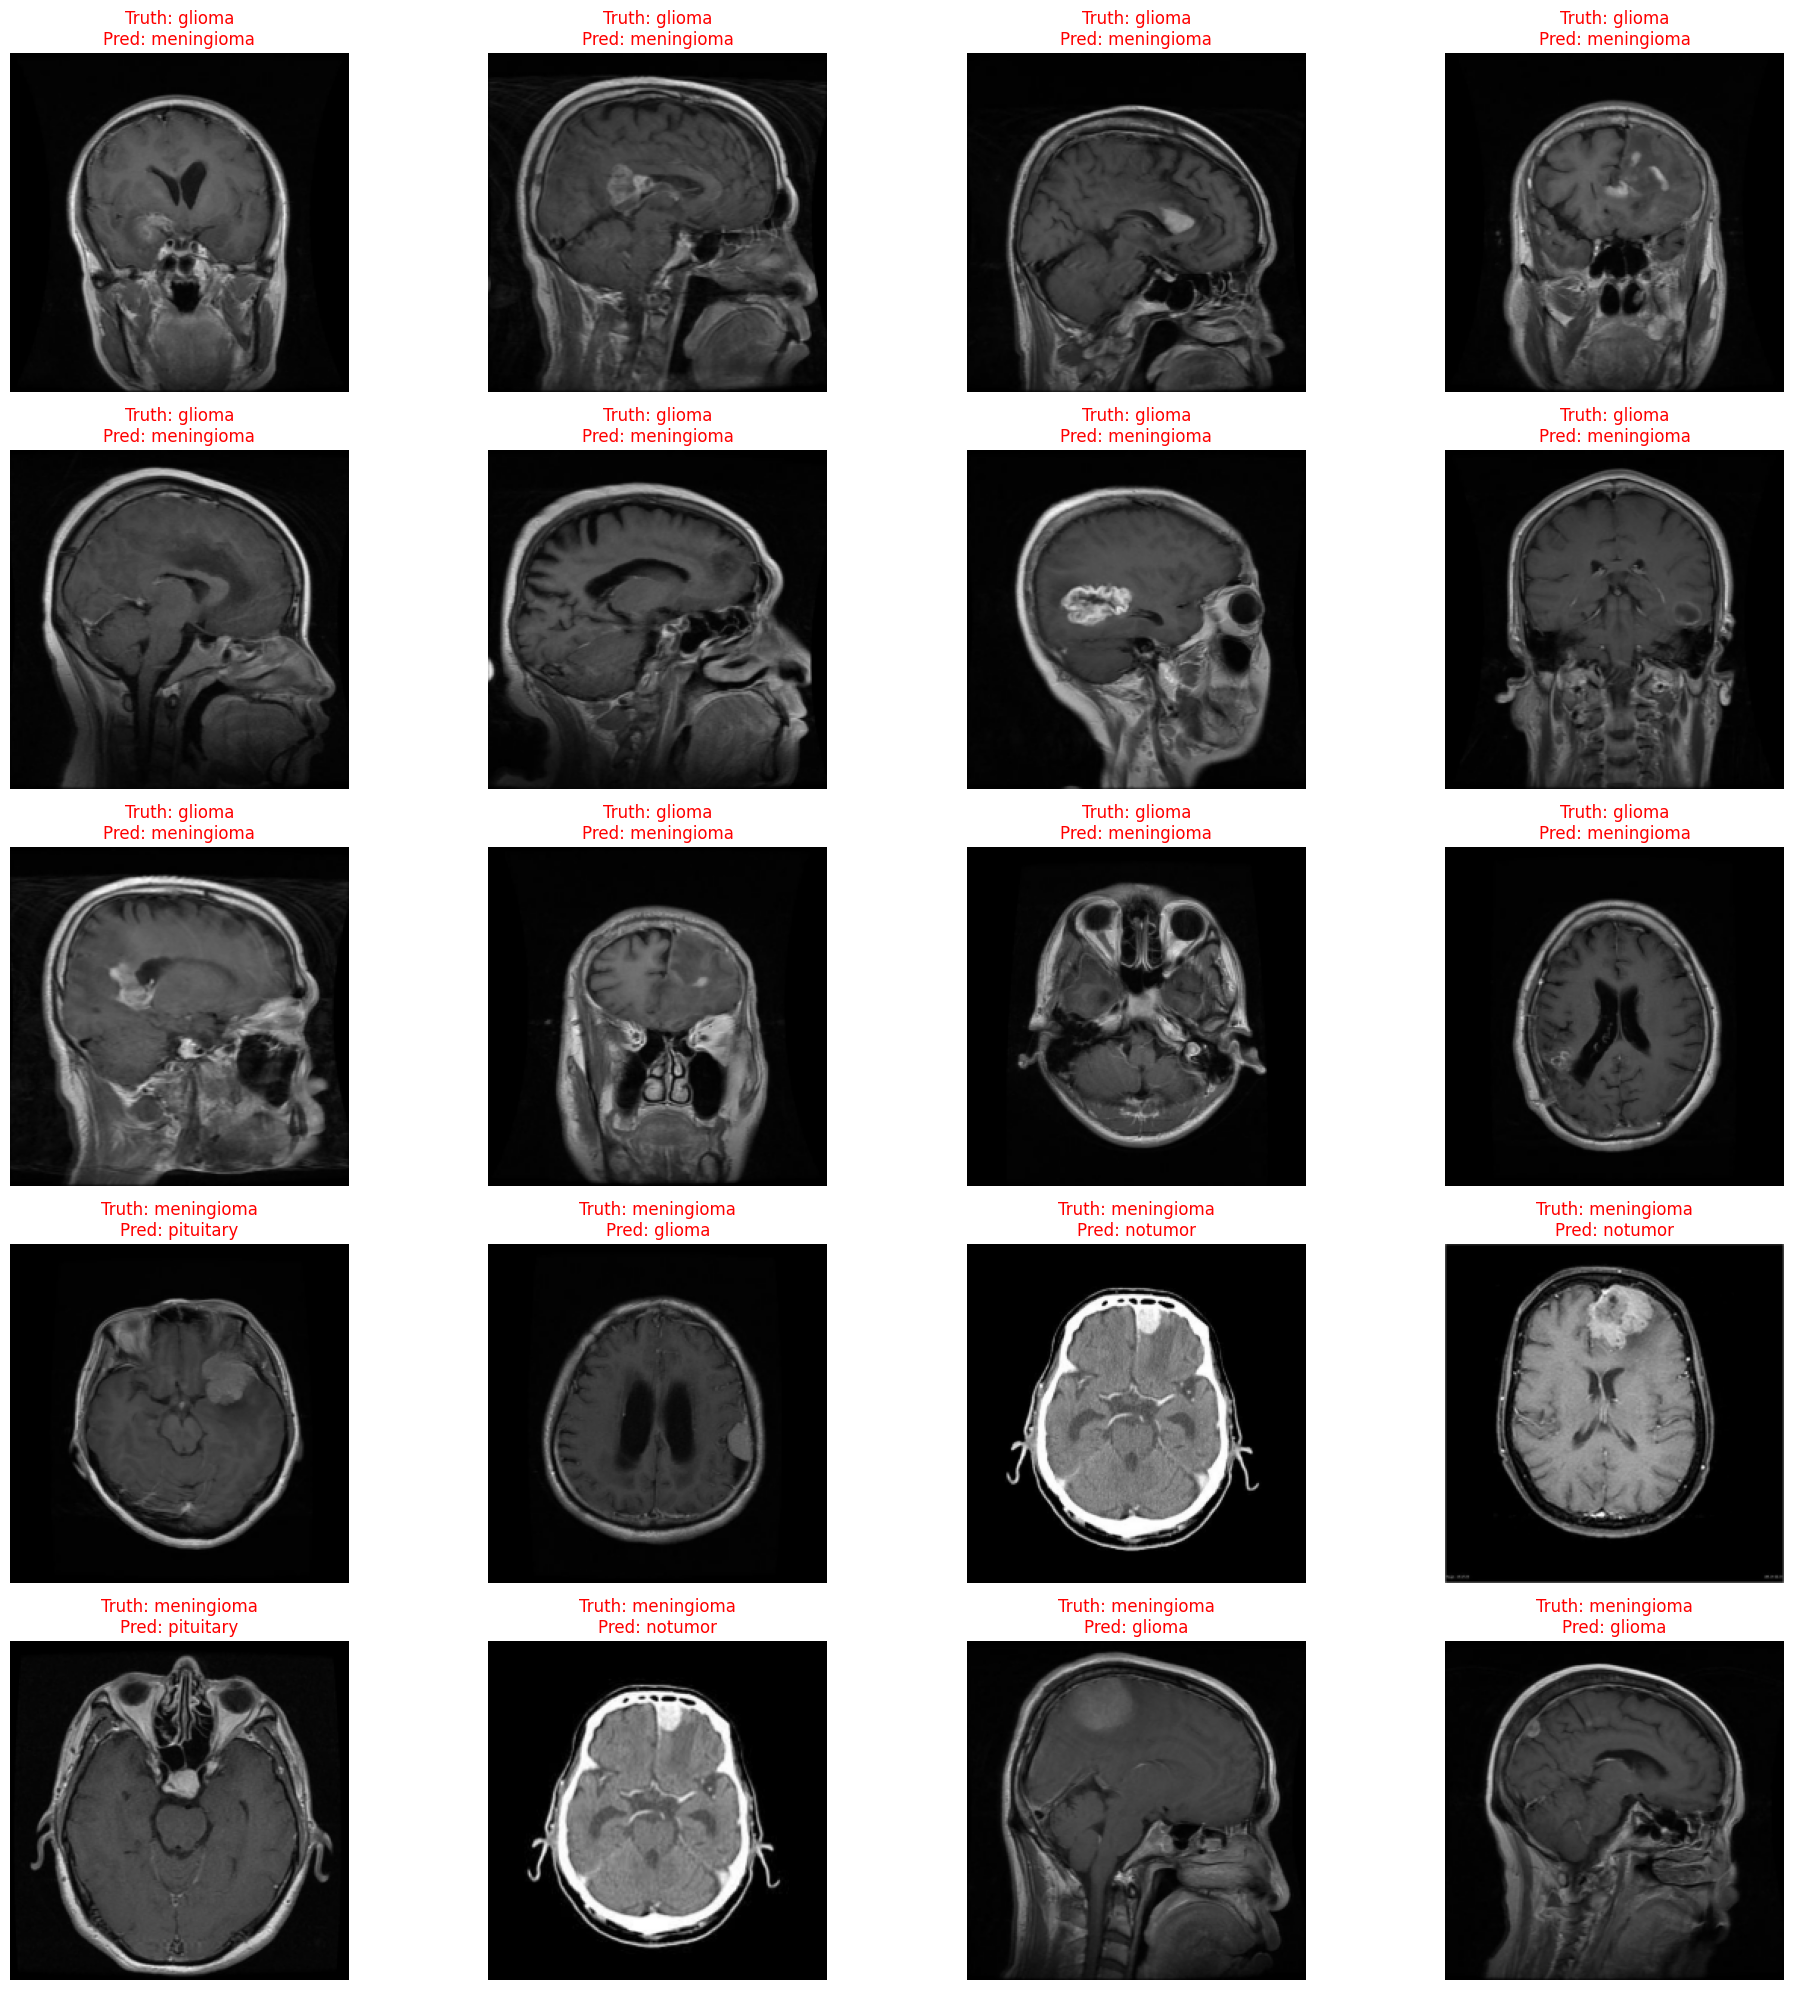

In [24]:
# identify misclassified indices
misclassified_indices = np.where(Y_test != y_pred_classes)[0]

# check if there are any misclassified samples
if len(misclassified_indices) == 0:
    print("No misclassified samples found!")
else:
    # limit the number of misclassified images to display (for visualization purposes)
    max_misclassified = 20 
    misclassified_indices = misclassified_indices[:max_misclassified]

    print(f"Visualizing {len(misclassified_indices)} Misclassified Samples...")
    plt.figure(figsize=(20, 20))

    for i, idx in enumerate(misclassified_indices):
        plt.subplot(5, 4, i + 1)  
        # apply deprocessing to the preprocessed image
        img = deprocess_input_caffe(X_test[idx])
        plt.imshow(img)
        plt.title(
            f"Truth: {labels[Y_test[idx]]}\nPred: {labels[y_pred_classes[idx]]}",
            color="red"
        )  # red text for better visibility
        plt.axis('off')

    plt.tight_layout()
    plt.show()

## 12. Evaluation Metrics and Confusion Matrix

we generate and visualise the confusion matrix and display the classification report to understand the model's performance in detail.

Generating Confusion Matrix...


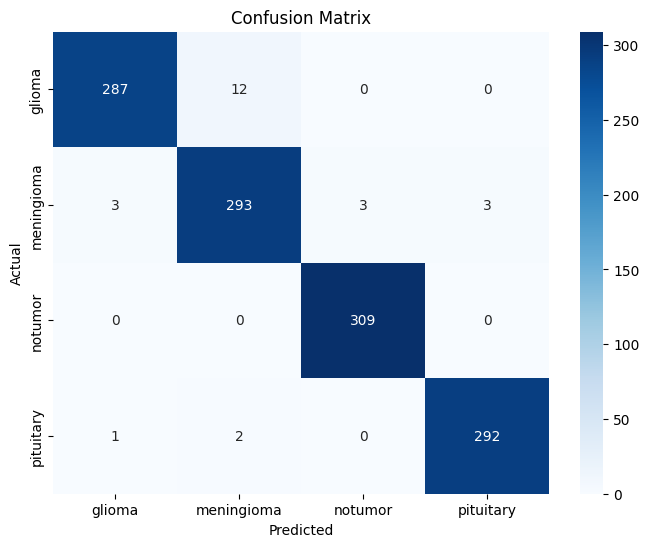


Classification Report:
              precision    recall  f1-score   support

      glioma       0.99      0.96      0.97       299
  meningioma       0.95      0.97      0.96       302
     notumor       0.99      1.00      1.00       309
   pituitary       0.99      0.99      0.99       295

    accuracy                           0.98      1205
   macro avg       0.98      0.98      0.98      1205
weighted avg       0.98      0.98      0.98      1205


Calculating Accuracy Score...
Accuracy on Test Set: 98.01%


In [25]:
print("Generating Confusion Matrix...")
cm = confusion_matrix(Y_test, y_pred_classes)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

print("\nClassification Report:")
print(classification_report(Y_test, y_pred_classes, target_names=labels))

print("\nCalculating Accuracy Score...")
accuracy = accuracy_score(Y_test, y_pred_classes)
print(f"Accuracy on Test Set: {accuracy * 100:.2f}%")

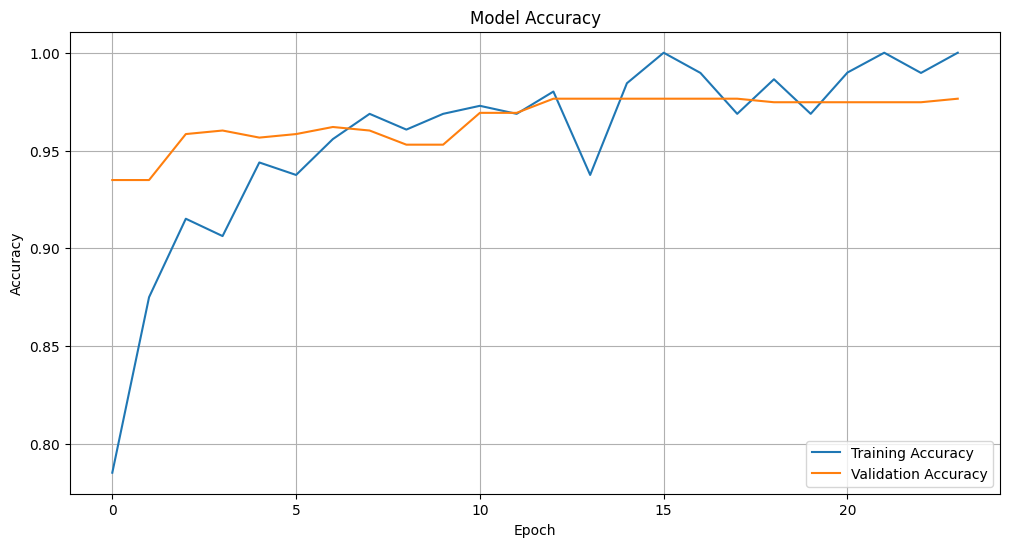

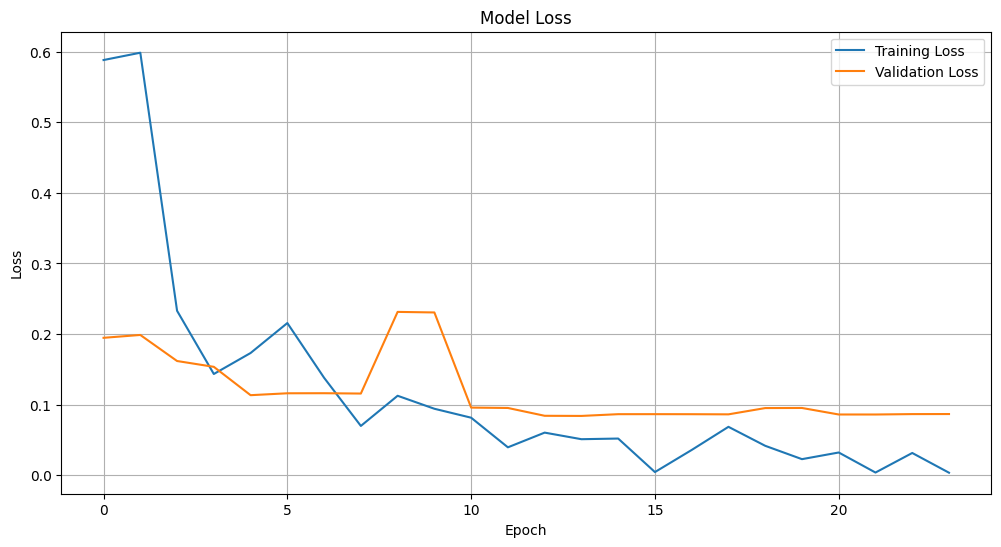

In [ ]:
import matplotlib.pyplot as plt

# plot Training and Validation Accuracy
plt.figure(figsize=(12, 6))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# plot Training and Validation Loss
plt.figure(figsize=(12, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

In [28]:
import shutil

# Compress 'Bmodel.keras' into 'model.zip' --> this is the model we load onto NeuroView AI
shutil.make_archive('model', 'zip', '.', 'Bmodel.keras')

'/kaggle/working/model.zip'